# Assignment 2: Network with convolutional filters

Source code: *Generative Deep Learning* (2nd ed.), David Foster, chapter 2.
`notebooks/02_deeplearning/02_cnn/convolutions.ipynb` and `cnn.ipynb` from `davidADSP/Generative_Deep_Learning_2nd_Edition`.

Two versions are built:

| | Version 1: original code | Version 2: my stride |
|---|---|---|
| Part A: hand-made edge filters (`convolutions.ipynb`) | stride 2 | **stride 3** |
| Part B: trained CNN on CIFAR-10 (`cnn.ipynb`) | `strides=2` in the 2nd and 4th Conv2D | **`strides=3`** in the same layers |

Nothing else changes: the filters, layers, optimizer (Adam, lr 0.0005), batch size 32 and 10 epochs all stay the same.

In [1]:
%matplotlib inline
import os, time
os.environ["KERAS_BACKEND"] = "tensorflow"
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.color import rgb2gray
from skimage.transform import resize

# Part A: Convolutional filters on an image (`convolutions.ipynb`)
## Original input image

(64, 64)


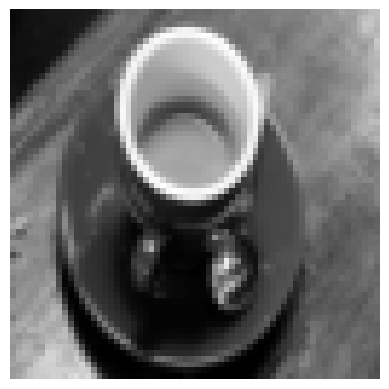

In [2]:
im = rgb2gray(data.coffee())
im = resize(im, (64, 64))
print(im.shape)
plt.axis("off")
plt.imshow(im, cmap="gray")

In [3]:
# The book's convolution loop, unchanged, wrapped in a function so it can be reused with any stride.
def conv_book(im, filt, stride):
    if stride == 1:
        new_image = np.zeros(im.shape)
    else:
        new_image = np.zeros((int(im.shape[0] / stride), int(im.shape[1] / stride)))
    im_pad = np.pad(im, 1, "constant")
    skipped = 0
    for i in range(0, im.shape[0], stride):
        for j in range(0, im.shape[1], stride):
            try:
                new_image[int(i / stride), int(j / stride)] = (
                    im_pad[i - 1, j - 1] * filt[0, 0]
                    + im_pad[i - 1, j] * filt[0, 1]
                    + im_pad[i - 1, j + 1] * filt[0, 2]
                    + im_pad[i, j - 1] * filt[1, 0]
                    + im_pad[i, j] * filt[1, 1]
                    + im_pad[i, j + 1] * filt[1, 2]
                    + im_pad[i + 1, j - 1] * filt[2, 0]
                    + im_pad[i + 1, j] * filt[2, 1]
                    + im_pad[i + 1, j + 1] * filt[2, 2]
                )
            except IndexError:
                skipped += 1   # the book uses a bare `except: pass`; here the silent skips are counted
    return new_image, skipped

filter1 = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]])    # horizontal edge filter
filter2 = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])    # vertical edge filter

## Filter outputs: stride 1, stride 2 (original), stride 3 (mine)

Horizontal edge  stride 1: output (64, 64), pixels  4096, positions silently skipped by try/except: 0
Horizontal edge  stride 2: output (32, 32), pixels  1024, positions silently skipped by try/except: 0
Horizontal edge  stride 3: output (21, 21), pixels   441, positions silently skipped by try/except: 43
Vertical edge    stride 1: output (64, 64), pixels  4096, positions silently skipped by try/except: 0
Vertical edge    stride 2: output (32, 32), pixels  1024, positions silently skipped by try/except: 0
Vertical edge    stride 3: output (21, 21), pixels   441, positions silently skipped by try/except: 43


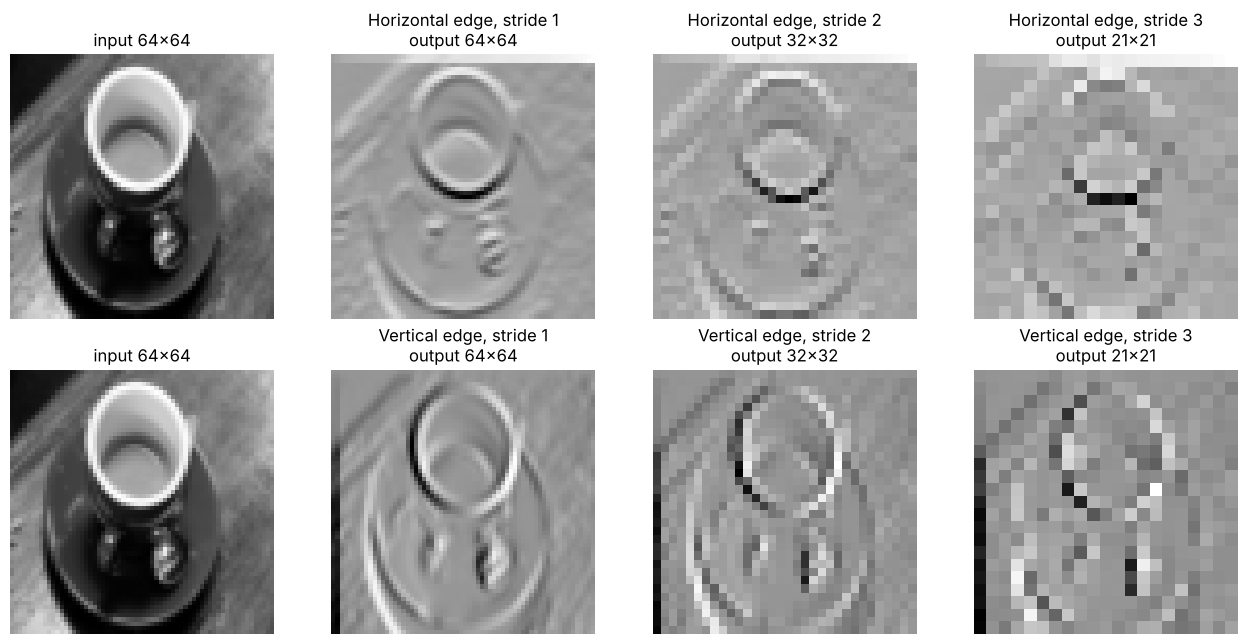

In [4]:
outs = {}
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for r, (fname, f) in enumerate([("Horizontal edge", filter1), ("Vertical edge", filter2)]):
    axes[r, 0].imshow(im, cmap="gray"); axes[r, 0].set_title("input 64×64"); axes[r, 0].axis("off")
    for c, s in enumerate([1, 2, 3]):
        out, skipped = conv_book(im, f, s)
        outs[(fname, s)] = out
        axes[r, c + 1].imshow(out, cmap="Greys"); axes[r, c + 1].axis("off")
        axes[r, c + 1].set_title(f"{fname}, stride {s}\noutput {out.shape[0]}×{out.shape[1]}")
        print(f"{fname:<16} stride {s}: output {out.shape}, pixels {out.size:>5}, "
              f"positions silently skipped by try/except: {skipped}")
plt.tight_layout(); plt.show()

### Checks on the output
A stride-*s* convolution should give the same result as the stride-1 output sampled every *s* pixels. The check below tests this, and also measures how much of the edge response (sum of |activation|, normalised per pixel) each stride keeps.

In [5]:
for fname in ["Horizontal edge", "Vertical edge"]:
    full = outs[(fname, 1)]
    for s in [2, 3]:
        o = outs[(fname, s)]
        sub = full[::s, ::s][: o.shape[0], : o.shape[1]]
        print(f"{fname:<16} stride {s}: equals stride-1 output sampled every {s} px -> {np.allclose(o, sub)}; "
              f"mean |response| {np.abs(o).mean():.3f} vs stride 1 {np.abs(full).mean():.3f}; "
              f"computations {o.size} vs {full.size} ({o.size / full.size:.0%})")

Horizontal edge  stride 2: equals stride-1 output sampled every 2 px -> True; mean |response| 0.202 vs stride 1 0.205; computations 1024 vs 4096 (25%)
Horizontal edge  stride 3: equals stride-1 output sampled every 3 px -> True; mean |response| 0.219 vs stride 1 0.205; computations 441 vs 4096 (11%)
Vertical edge    stride 2: equals stride-1 output sampled every 2 px -> True; mean |response| 0.242 vs stride 1 0.243; computations 1024 vs 4096 (25%)
Vertical edge    stride 3: equals stride-1 output sampled every 3 px -> True; mean |response| 0.253 vs stride 1 0.243; computations 441 vs 4096 (11%)


### Stride-3 version written so no position is lost
With stride 3, the loop visits ceil(64/3) = 22 positions per axis, but the book's output array holds only int(64/3) = 21.
The book wraps the loop in `try/except: pass`, so the last row and column are dropped without any error.
The general formula for the output size is `ceil(n / stride)` (with this "same"-style padding):

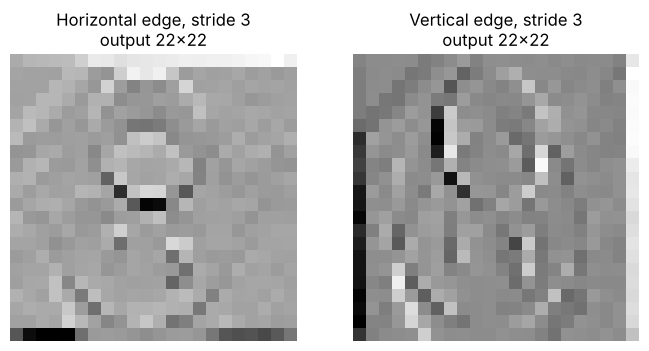

In [6]:
def conv_strided(im, filt, stride):
    n = int(np.ceil(im.shape[0] / stride)); m = int(np.ceil(im.shape[1] / stride))
    im_pad = np.pad(im, 1, "constant")
    out = np.zeros((n, m))
    for a, i in enumerate(range(0, im.shape[0], stride)):
        for b, j in enumerate(range(0, im.shape[1], stride)):
            out[a, b] = np.sum(im_pad[i:i + 3, j:j + 3] * filt)   # window centred on pixel (i, j)
    return out

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, (fname, f) in zip(axes, [("Horizontal edge", filter1), ("Vertical edge", filter2)]):
    o = conv_strided(im, f, 3)
    ax.imshow(o, cmap="Greys"); ax.axis("off"); ax.set_title(f"{fname}, stride 3\noutput {o.shape[0]}×{o.shape[1]}")
plt.tight_layout(); plt.show()

# Part B: Trained CNN on CIFAR-10 (`cnn.ipynb`)

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, utils, datasets

NUM_CLASSES = 10
CLASSES = np.array(["airplane", "automobile", "bird", "cat", "deer",
                    "dog", "frog", "horse", "ship", "truck"])
try:
    (x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()
except Exception:
    # Fallback when the Keras download host is unreachable: CIFAR-10 saved locally as .npz
    d = np.load("data/cifar10.npz")
    x_train, y_train, x_test, y_test = d["x_train"], d["y_train"], d["x_test"], d["y_test"]

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
y_train = utils.to_categorical(y_train, NUM_CLASSES)
y_test = utils.to_categorical(y_test, NUM_CLASSES)
print(x_train.shape, x_test.shape)

I0000 00:00:1793477340.489855    1482 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793477340.644051    1482 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793477342.432299    1482 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


(50000, 32, 32, 3) (10000, 32, 32, 3)


In [8]:
def build_model(stride):
    # The book's architecture. `stride` replaces the hard-coded strides=2 in conv layers 2 and 4.
    input_layer = layers.Input((32, 32, 3))
    x = layers.Conv2D(filters=32, kernel_size=3, strides=1, padding="same")(input_layer)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Conv2D(filters=32, kernel_size=3, strides=stride, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Conv2D(filters=64, kernel_size=3, strides=1, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Conv2D(filters=64, kernel_size=3, strides=stride, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Dropout(rate=0.5)(x)
    x = layers.Dense(NUM_CLASSES)(x)
    output_layer = layers.Activation("softmax")(x)
    return models.Model(input_layer, output_layer, name=f"cnn_stride{stride}")

## Version 1: original (strides=2)

In [9]:
tf.keras.utils.set_random_seed(42)
model = build_model(stride=2)
model.summary()

Model: "cnn_stride2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 592,554 (2.26 MB)

Trainable params: 591,914 (2.26 MB)

Non-trainable params: 640 (2.50 KB)

## Version 2: my stride (strides=3)

In [10]:
tf.keras.utils.set_random_seed(42)
model_s3 = build_model(stride=3)
model_s3.summary()

Model: "cnn_stride3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 11, 11, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 199,338 (778.66 KB)

Trainable params: 198,698 (776.16 KB)

Non-trainable params: 640 (2.50 KB)

## Output shapes and parameter counts

In [11]:
def conv_shapes(m):
    return [tuple(l.output.shape[1:]) for l in m.layers if isinstance(l, (layers.Conv2D, layers.Flatten))]
names = ["conv1 (s=1)", "conv2 (strided)", "conv3 (s=1)", "conv4 (strided)", "flatten"]
print(f"{'layer':<18}{'stride 2':<18}{'stride 3':<18}")
for n, a, b in zip(names, conv_shapes(model), conv_shapes(model_s3)):
    print(f"{n:<18}{str(a):<18}{str(b):<18}")
dense = lambda m: [l for l in m.layers if isinstance(l, layers.Dense)][0].count_params()
print(f"\n{'total params':<18}{model.count_params():<18,}{model_s3.count_params():<18,}")
print(f"{'Dense(128) params':<18}{dense(model):<18,}{dense(model_s3):<18,}")

layer             stride 2          stride 3          
conv1 (s=1)       (32, 32, 32)      (32, 32, 32)      
conv2 (strided)   (16, 16, 32)      (11, 11, 32)      
conv3 (s=1)       (16, 16, 64)      (11, 11, 64)      
conv4 (strided)   (8, 8, 64)        (4, 4, 64)        
flatten           (4096,)           (1024,)           

total params      592,554           199,338           
Dense(128) params 524,416           131,200           


## Train both models (book settings: Adam lr=0.0005, batch 32, 10 epochs, validation on test set)

In [12]:
histories, results = {}, {}
for name, m in [("Original (stride 2)", model), ("My stride (stride 3)", model_s3)]:
    tf.keras.utils.set_random_seed(42)
    m.compile(loss="categorical_crossentropy",
              optimizer=optimizers.Adam(learning_rate=0.0005), metrics=["accuracy"])
    t0 = time.time()
    h = m.fit(x_train, y_train, batch_size=32, epochs=10, shuffle=True,
              validation_data=(x_test, y_test), verbose=2)
    secs = time.time() - t0
    loss, acc = m.evaluate(x_test, y_test, batch_size=1000, verbose=0)
    histories[name] = h.history
    results[name] = dict(params=m.count_params(), train_acc=h.history["accuracy"][-1],
                         test_acc=acc, test_loss=loss, best_val=max(h.history["val_accuracy"]),
                         sec_epoch=secs / 10)
    print(f"==> {name}: test loss {loss:.4f}, test accuracy {acc:.4f}\n")

Epoch 1/10


1563/1563 - 100s - 64ms/step - accuracy: 0.4675 - loss: 1.5303 - val_accuracy: 0.5611 - val_loss: 1.2416


Epoch 2/10


1563/1563 - 132s - 84ms/step - accuracy: 0.5980 - loss: 1.1413 - val_accuracy: 0.6310 - val_loss: 1.0426


Epoch 3/10


1563/1563 - 142s - 91ms/step - accuracy: 0.6450 - loss: 1.0155 - val_accuracy: 0.6084 - val_loss: 1.1206


... (32 outputs left out)

1563/1563 - 86s - 55ms/step - accuracy: 0.7207 - loss: 0.7918 - val_accuracy: 0.6377 - val_loss: 1.0606


Epoch 10/10


1563/1563 - 60s - 38ms/step - accuracy: 0.7326 - loss: 0.7557 - val_accuracy: 0.6242 - val_loss: 1.1135


==> My stride (stride 3): test loss 1.1135, test accuracy 0.6242



## Evaluation: side-by-side

In [13]:
print(f"{'':<22}{'params':>10}{'train acc':>11}{'test acc':>10}{'best val':>10}{'test loss':>11}{'gap':>7}{'s/epoch':>9}")
for n, r in results.items():
    print(f"{n:<22}{r['params']:>10,}{r['train_acc']:>11.4f}{r['test_acc']:>10.4f}{r['best_val']:>10.4f}"
          f"{r['test_loss']:>11.4f}{r['train_acc'] - r['test_acc']:>7.3f}{r['sec_epoch']:>9.1f}")

                          params  train acc  test acc  best val  test loss    gap  s/epoch
Original (stride 2)      592,554     0.7634    0.6551    0.6701     1.0460  0.108    102.3
My stride (stride 3)     199,338     0.7326    0.6242    0.6536     1.1135  0.108     61.0


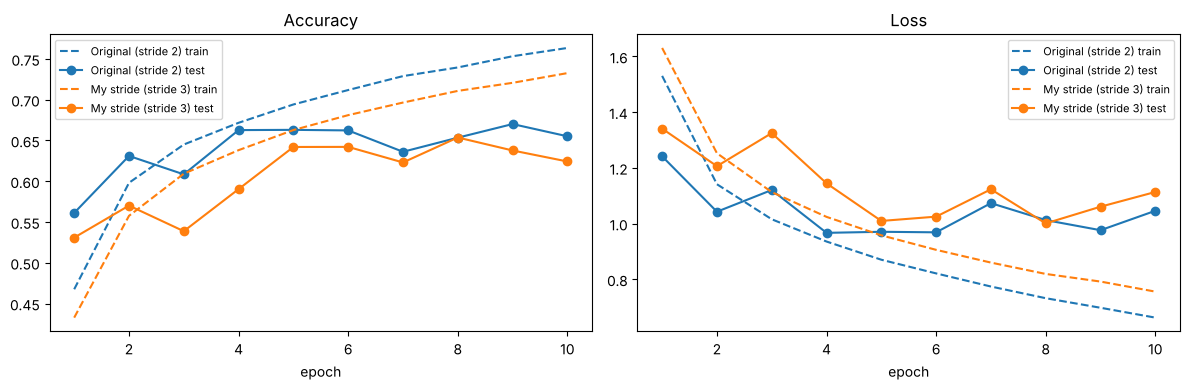

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ep = range(1, 11)
for (n, h), col in zip(histories.items(), ["tab:blue", "tab:orange"]):
    ax[0].plot(ep, h["accuracy"], "--", color=col, label=f"{n} train")
    ax[0].plot(ep, h["val_accuracy"], "-o", color=col, label=f"{n} test")
    ax[1].plot(ep, h["loss"], "--", color=col, label=f"{n} train")
    ax[1].plot(ep, h["val_loss"], "-o", color=col, label=f"{n} test")
ax[0].set_title("Accuracy"); ax[1].set_title("Loss")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Accuracy per class

In [15]:
actual = np.argmax(y_test, axis=-1)
pred = {n: np.argmax(m.predict(x_test, verbose=0), axis=-1)
        for n, m in [("Original (stride 2)", model), ("My stride (stride 3)", model_s3)]}
print(f"{'class':<12}{'stride 2':>10}{'stride 3':>10}{'diff':>8}")
for k, c in enumerate(CLASSES):
    a2 = (pred['Original (stride 2)'][actual == k] == k).mean()
    a3 = (pred['My stride (stride 3)'][actual == k] == k).mean()
    print(f"{c:<12}{a2:>10.3f}{a3:>10.3f}{a3 - a2:>+8.3f}")
agree = (pred['Original (stride 2)'] == pred['My stride (stride 3)']).mean()
print(f"\nThe two models give the same prediction on {agree:.1%} of test images")

class         stride 2  stride 3    diff
airplane         0.767     0.836  +0.069
automobile       0.744     0.804  +0.060
bird             0.340     0.525  +0.185
cat              0.411     0.478  +0.067
deer             0.577     0.285  -0.292
dog              0.752     0.522  -0.230
frog             0.584     0.912  +0.328
horse            0.776     0.661  -0.115
ship             0.767     0.606  -0.161
truck            0.833     0.613  -0.220

The two models give the same prediction on 62.7% of test images


## Sample predictions (same 10 images for both models)

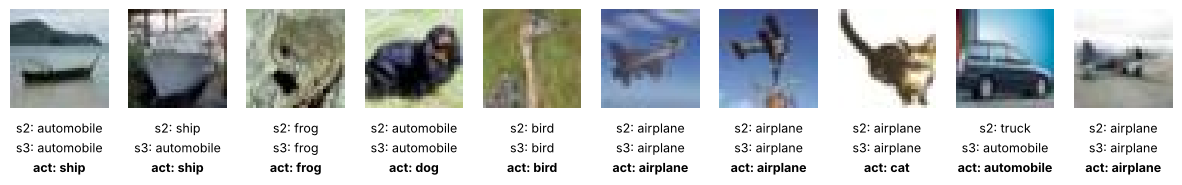

In [16]:
rng = np.random.default_rng(0)
indices = rng.choice(len(x_test), 10, replace=False)
fig = plt.figure(figsize=(15, 3.4))
for i, idx in enumerate(indices):
    ax = fig.add_subplot(1, 10, i + 1); ax.axis("off"); ax.imshow(x_test[idx])
    ax.text(0.5, -0.25, "s2: " + CLASSES[pred['Original (stride 2)'][idx]], fontsize=9, ha="center", transform=ax.transAxes)
    ax.text(0.5, -0.45, "s3: " + CLASSES[pred['My stride (stride 3)'][idx]], fontsize=9, ha="center", transform=ax.transAxes)
    ax.text(0.5, -0.65, "act: " + CLASSES[actual[idx]], fontsize=9, ha="center", transform=ax.transAxes, weight="bold")
plt.show()

## Feature maps: the output after the first strided convolution

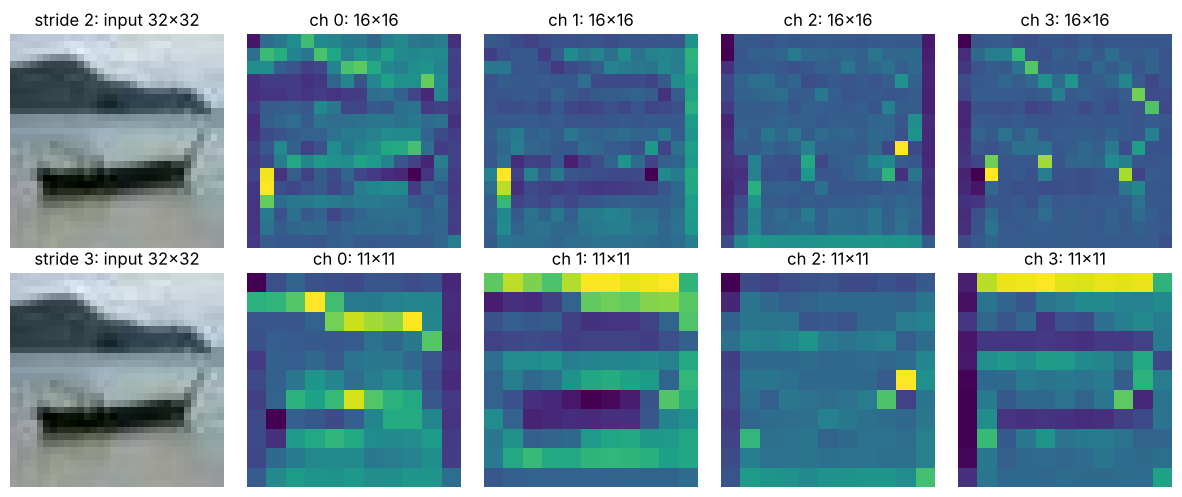

In [17]:
img = x_test[indices[:1]]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for r, (n, m) in enumerate([("stride 2", model), ("stride 3", model_s3)]):
    strided = [l for l in m.layers if isinstance(l, layers.LeakyReLU)][1]   # activation after conv2
    fm = np.asarray(models.Model(m.input, strided.output)(img, training=False))[0]
    axes[r, 0].imshow(img[0]); axes[r, 0].set_title(f"{n}: input 32×32"); axes[r, 0].axis("off")
    for j in range(4):
        axes[r, j + 1].imshow(fm[:, :, j], cmap="viridis"); axes[r, j + 1].axis("off")
        axes[r, j + 1].set_title(f"ch {j}: {fm.shape[0]}×{fm.shape[1]}")
plt.tight_layout(); plt.show()

# Interpretation of output and accuracy

## Part A: filter output
- **Same detector, sparser sampling.** The stride-2 and stride-3 outputs exactly equal the stride-1 output sampled every 2nd or 3rd pixel (checked with `np.allclose`). Stride does not change what a filter detects. It only changes how many positions are kept: about 1/stride² of them (64×64 → 32×32 → 21×21).
- **Visible effect.** At stride 2 the cup's rim and the saucer stay continuous. At stride 3 they become dotted and blocky, because a thin edge can fall between two sampled positions (aliasing).
- **A bug that only shows up with stride 3.** The book sizes the output as `int(64/stride)`, which is 21, but the loop visits `ceil(64/3)` = 22 positions per axis. The bare `try/except: pass` hides the IndexError, so 43 values (the last row and column) are dropped silently. With stride 2 the division is exact and nothing is lost. The corrected version above uses `ceil` and gives 22×22.

## Part B: CNN accuracy on CIFAR-10
| | Stride 2 (original) | Stride 3 (mine) |
|---|---|---|
| Map after conv2 / conv4 | 16×16 / 8×8 | 11×11 / 4×4 |
| Parameters | 592,554 | 199,338 (−66%) |
| Final train accuracy | 76.3% | 73.3% |
| Final test accuracy | **65.5%** | **62.4%** |
| Best test accuracy (any epoch) | 67.0% | 65.4% |
| Mean test accuracy, epochs 8–10 | 66.0% | 63.9% |
| Train–test gap | 10.8 pts | 10.8 pts |
| Time per epoch | ~80–100 s | ~55–60 s |

1. **Why accuracy drops.** Stride 3 keeps about 1/9 of the positions per strided layer, against 1/4 at stride 2. The final map is 4×4 instead of 8×8, so small cues are merged or skipped. CIFAR-10 images are only 32×32, so they can't spare that detail. Stride 3 was behind at 9 of the 10 epochs.
2. **It is underfitting, not overfitting.** Training accuracy is also lower, and the train–test gap is identical at 10.8 points. Having fewer parameters did not make the model generalise better; it just fit the data less well.
3. **Where the savings come from.** Almost all of the parameter drop is in the Dense layer (524k → 131k), because the flattened vector shrinks from 4,096 to 1,024. The conv layers have the same number of weights in both models. Fewer positions per layer also means faster epochs.
4. **Both models start to overfit after about epoch 5.** Test loss creeps up while training loss keeps falling, and test accuracy plateaus around 63–66%.
5. **Per-class differences are mostly noise.** For example, stride 3 scored 33 points higher on frog and 29 points lower on deer. But test accuracy swings by 2–3 points between epochs, and the two models agree on only 62.7% of test images.

**Takeaway:** a larger stride trades accuracy for size and speed. Here stride 3 cost about 2–3 points of accuracy for 66% fewer parameters and roughly 35% less training time. For 32×32 images, the book's stride of 2 is the better balance.

**Caveats.** Each model was trained once with one seed. As in the book, the test set doubles as validation data, so the "best epoch" numbers are slightly optimistic. A JPEG copy of CIFAR-10 was used because the Keras download host was unreachable from the training machine. Both models used the same data, so the comparison between them is fair.
